### Basic site generation for ONE timestep

In [ ]:
### BASE GENERATION ###
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
import plotly.graph_objects as go
from scipy.spatial import cKDTree
from scipy.stats import multivariate_normal

### Functions ----------------------------------------------------------------------------------------------------------
# custom normalization function
def my_normalize(coords, padding_factor):
    # normalizes all coordinates to be within a box around center [-1, 1]
    # padding_factor makes the points fit into an even smaller box (if > 1.0)
    x_max = np.max(coords[:, 0])
    x_min = np.min(coords[:, 0])
    y_max = np.max(coords[:, 1])
    y_min = np.min(coords[:, 1])
    x_delta = x_max - x_min
    y_delta = y_max - y_min
    x_mean = (x_max + x_min) / 2
    y_mean = (y_max + y_min) / 2
    
    coords_normalized = np.zeros(coords.shape)
    coords_normalized[:, 0] = (coords[:, 0] - x_mean) / (0.5 * x_delta * padding_factor) 
    coords_normalized[:, 1] = (coords[:, 1] - y_mean) / (0.5 * y_delta * padding_factor)    
    return coords_normalized

# Formula for the atmospheric dispersion (single number) np.where(condition, return when true, return when false)
def atmospheric_dispersion(x, y, Q, u):
    def w(u):
        # weighting function for high wind influence
        result = np.where(u>=0, (20*u*np.exp(-3*u))/(2.15 + u), 0)
        return result
    
    def lo(x, u, Q):
        # x-axis distribution in low wind conditions
        result = np.exp((-(x**2))/(10**(-5)*(0.5 + u)**(-14)) )*(Q/(u + 0.1))
        return result
    
    def hi(x, u, Q):
        # x-axis distribution in high wind conditions
        result = np.where(x>=0, (1/(6*x+1))*(Q/(u + 0.1)), lo(x, u, Q))
        return result
    
    def C_x(x, u, Q):
        # x-axis weighted combination of high and low wind conditions 
        result = lo(x, u, Q) + w(u)*hi(x, u, Q)
        return result
    
    def sigma(x, u):
        # balance function for transitioning from upwind (x<0) to downwind (x>0) + at small u's basicall only the upwind condition (gaussian round plume) should be used and at high u's only the downwind 1/x plume.
        result = np.where(x>0, np.where(u>0, 1/(1+np.exp(7*(7*np.abs(x)**0.1 + 10*np.abs(u)**0.8 - 9))), 1), 1)
        return result
    
    def cross(x, y):
        # y-axis crosswind function (gaussian bell that gets progressively wider and lower)
        a = 0.025
        result = np.where(x>0, np.exp(-(y**2)/(a*x**2)), 0)
        return result
    
    def C(x, y, u, Q):
        # total combination. Returns the full concentration function
        result = np.where(x<=0, 
                          np.sqrt(C_x(x, u, Q)*lo(y, u, Q)), 
                          np.sqrt(C_x(x, u, Q)*(sigma(x, u)*lo(y, u, Q) + cross(x, y)))
                          )
        return result
    
    return C(x, y, u, Q)

# coordinate transformations to go from global grid to local frame (wind direction = x, and crosswind = y)   
def coordinate_transform_scalar(x, y, px, py, wind_direc):
    # takes in global coordinates and spits out their representation in the local coordinate frame of one source + wind
    # px, py are the source coordinates
    # dir is the wind direction
    vec = np.array([x-px, y-py])
    wind = np.array([np.cos(wind_direc), np.sin(wind_direc)])
    
    x_local = np.dot(vec, wind)
    y_local = np.linalg.norm(vec - x_local*wind)
    
    return x_local, y_local

def coordinate_transform_array(X, Y, px, py, wind_direc):
    # takes in global coordinates and spits out their representation in the local coordinate frame of one source + wind
    # px, py are the source coordinates
    # dir is the wind direction
    X = X-px
    Y = Y-py
    # this is now an array of all the vectors @every point in the input grid
    XY = np.stack([X, Y])
    WIND = np.zeros(XY.shape)
    WIND[0, :, :] = np.cos(wind_direc)
    WIND[1, :, :] = np.sin(wind_direc)
    
    # x_local = np.dot(vec, wind)
    X_local = XY[0, :, :] * WIND[0, :, :] + XY[1, :, :] * WIND[1, :, :]
    
    # y_local = np.linalg.norm(vec - x_local*wind)
    Y_local = np.linalg.norm(XY - X_local * WIND, axis=0)

    return X_local, Y_local

# poisson disk sampling to create a uniformly distributed sensor pattern
def optimized_poisson_disk_sampling(min_points, max_points, k=30, radius_multiplier=1.1, padding=0.05):
    # Set the width and height for the square from -1 to 1
    width, height = 2, 2  # Effective area from -1 to 1 (centered at 0)
    
    # Randomly choose the number of points within the specified range
    num_points = np.random.randint(min_points, max_points + 1)
    
    # Calculate approximate radius based on desired number of points and apply multiplier
    base_radius = np.sqrt((width * height) / (num_points * np.pi))
    radius = base_radius * radius_multiplier
    
    # Create an empty list for storing points
    points = []
    
    # Grid size based on calculated radius
    cell_size = radius / np.sqrt(2)
    grid_width = int(np.ceil(width / cell_size))
    grid_height = int(np.ceil(height / cell_size))
    
    # Create grid with empty cells
    grid = -np.ones((grid_width, grid_height), dtype=int)
    
    # Generate the first point
    initial_point = np.array([np.random.uniform(-1, 1), np.random.uniform(-1, 1)])
    points.append(initial_point)
    grid[int((initial_point[0] + 1) / cell_size), int((initial_point[1] + 1) / cell_size)] = 0
    
    # List of active points
    active_points = [0]
    
    # Start the algorithm
    while active_points and len(points) < num_points:
        # Choose a random index from active points
        idx = np.random.choice(active_points)
        base_point = points[idx]
        
        found_new_point = False
        for _ in range(k):
            # Generate a new point around the base point within [radius, 2*radius]
            angle = np.random.uniform(0, 2 * np.pi)
            distance = np.random.uniform(radius, 2 * radius)
            new_point = base_point + distance * np.array([np.cos(angle), np.sin(angle)])
            
            # Check if the new point is within bounds
            if not (-1 <= new_point[0] <= 1 and -1 <= new_point[1] <= 1):
                continue
            
            # Calculate the grid cell of the new point
            grid_x, grid_y = int((new_point[0] + 1) / cell_size), int((new_point[1] + 1) / cell_size)
            
            # Check neighboring cells for minimum distance constraint
            nearby_points = []
            for i in range(max(grid_x - 2, 0), min(grid_x + 3, grid_width)):
                for j in range(max(grid_y - 2, 0), min(grid_y + 3, grid_height)):
                    if grid[i, j] != -1:
                        nearby_points.append(points[grid[i, j]])
            
            if nearby_points:
                # Use a KDTree for efficient distance checking
                tree = cKDTree(nearby_points)
                if np.min(tree.query([new_point], k=1)[0]) < radius:
                    continue
            
            # Add new point to list and grid
            points.append(new_point)
            active_points.append(len(points) - 1)
            grid[grid_x, grid_y] = len(points) - 1
            found_new_point = True
            break
        
        if not found_new_point:
            # No valid points found; deactivate the point
            active_points.remove(idx)
    
    points = np.array(points[:num_points])  # Ensure exact number of points
    
    # Stretch and translate points to fit within the padded area of [-1, 1]
    min_x, min_y = points[:, 0].min(), points[:, 1].min()
    max_x, max_y = points[:, 0].max(), points[:, 1].max()
    
    # Effective width and height within padding
    effective_width = width - 2 * padding
    effective_height = height - 2 * padding
    
    # Scale points to fit within the effective area and apply padding
    points[:, 0] = (points[:, 0] - min_x) / (max_x - min_x) * effective_width + (-1 + padding)
    points[:, 1] = (points[:, 1] - min_y) / (max_y - min_y) * effective_height + (-1 + padding)

    return points



### Main ---------------------------------------------------------------------------------------------------------------
# random number of sources (5-30)
N_sources = np.random.randint(5, 31)

# random source locations (x, y)
pos_sources = np.random.randn(N_sources, 2)
pos_sources = my_normalize(pos_sources, padding_factor=1.5)

# random sensor locations (x, y)
pos_sensors = np.array(optimized_poisson_disk_sampling(min_points=5, max_points=8))

# random wind-speed [0, 2pi] and wind-direction [0, 1]
wind_speed = np.random.rand()
wind_direc = 2 * np.pi * np.random.rand()
Q = np.random.rand()

# generate some concentration data
px,      py      = pos_sources[0, :]
x,       y       = np.linspace(-1, 1, 128), np.linspace(-1, 1, 128)
X,       Y       = np.meshgrid(x, y)
X_local, Y_local = coordinate_transform_array(X, Y, px, py, wind_direc)

Z = atmospheric_dispersion(X_local, Y_local, Q, wind_speed)
levels = np.linspace(Z.min(), Z.max(), 20)



# plot map -------------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots()
contour = ax.contourf(X, Y, Z, levels=10, cmap="viridis")
colorbar = fig.colorbar(contour, ax=ax, label="Concentration")
colorbar.ax.set_position([0.82, 0.1, 0.5, 0.6])  # [left, bottom, width, height]
ax.arrow(0, 0, wind_speed*np.cos(wind_direc), wind_speed*np.sin(wind_direc), color="lightblue", width=0.02)
ax.scatter(pos_sources[:, 0], pos_sources[:, 1], 
        color="black", edgecolors="lightgrey", linewidths=0.7, label=f"{N_sources} Sources", s=40)
ax.scatter(pos_sensors[:, 0], pos_sensors[:, 1], 
        color="firebrick", edgecolors="lightgrey", linewidths=0.7, marker="p", label=f"{len(pos_sensors)} Sensors", s=100)
ax.plot([], [], "->", color="cyan", label=f"{wind_speed:.2f} Windsp.")
ax.plot([], [], "o", color="purple", label=f"{Q:.2f} Emiss. ")

ax.set_title("Oil Site")
ax.set_xlabel("y distance in unit")
ax.set_ylabel("x distance in unit")
ax.set_aspect("equal", adjustable="box")
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2))
ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.94))
ax.grid(visible=True, color="lightgray")



### Site generation for MULTI Timestep

In [ ]:
### BASE GENERATION ###
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.spatial import cKDTree
from scipy.stats import multivariate_normal

### Functions ----------------------------------------------------------------------------------------------------------
# custom normalization function
def my_normalize(coords, padding_factor):
    # normalizes all coordinates to be within a box around center [-1, 1]
    # padding_factor makes the points fit into an even smaller box (if > 1.0)
    x_max = np.max(coords[:, 0])
    x_min = np.min(coords[:, 0])
    y_max = np.max(coords[:, 1])
    y_min = np.min(coords[:, 1])
    x_delta = x_max - x_min
    y_delta = y_max - y_min
    x_mean = (x_max + x_min) / 2
    y_mean = (y_max + y_min) / 2
    
    coords_normalized = np.zeros(coords.shape)
    coords_normalized[:, 0] = (coords[:, 0] - x_mean) / (0.5 * x_delta * padding_factor) 
    coords_normalized[:, 1] = (coords[:, 1] - y_mean) / (0.5 * y_delta * padding_factor)    
    return coords_normalized


# Formula for the atmospheric dispersion (single number) np.where(condition, return when true, return when false)
def atmospheric_dispersion(x, y, Q, u):
    def w(u):
        # weighting function for high wind influence
        result = np.where(u>=0, (20*u*np.exp(-3*u))/(2.15 + u), 0)
        return result
    
    def lo(x, u, Q):
        # x-axis distribution in low wind conditions
        result = np.exp((-(x**2))/(10**(-5)*(0.5 + u)**(-14)) )*(Q/(u + 0.1))
        return result
    
    def hi(x, u, Q):
        # x-axis distribution in high wind conditions
        result = np.where(x>=0, (1/(6*x+1))*(Q/(u + 0.1)), lo(x, u, Q))
        return result
    
    def C_x(x, u, Q):
        # x-axis weighted combination of high and low wind conditions 
        result = lo(x, u, Q) + w(u)*hi(x, u, Q)
        return result
    
    def sigma(x, u):
        # balance function for transitioning from upwind (x<0) to downwind (x>0) + at small u"s basicall only the upwind condition (gaussian round plume) should be used and at high u"s only the downwind 1/x plume.
        result = np.where(x>0, np.where(u>0, 1/(1+np.exp(7*(7*np.abs(x)**0.1 + 10*np.abs(u)**0.8 - 9))), 1), 1)
        return result
    
    def cross(x, y):
        # y-axis crosswind function (gaussian bell that gets progressively wider and lower)
        a = 0.02
        result = np.where(x>0, np.exp(-(y**2)/(a*x**2)), 0)
        return result
    
    def C(x, y, u, Q):
        # total combination. Returns the full concentration function
        result = np.where(x<=0, 
                          np.sqrt(C_x(x, u, Q)*lo(y, u, Q)), 
                          np.sqrt(C_x(x, u, Q)*(sigma(x, u)*lo(y, u, Q) + cross(x, y)))
                          )
        return result
    
    return C(x, y, u, Q)


# coordinate transformations to go from global grid to local frame (wind direction = x, and crosswind = y)   
def coordinate_transform_scalar(x, y, px, py, wind_direc):
    # takes in global coordinates and spits out their representation in the local coordinate frame of one source + wind
    # px, py are the source coordinates
    # dir is the wind direction
    vec = np.array([x-px, y-py])
    wind = np.array([np.cos(wind_direc), np.sin(wind_direc)])
    
    x_local = np.dot(vec, wind)
    y_local = np.linalg.norm(vec - x_local*wind)
    
    return x_local, y_local

def coordinate_transform_array(X, Y, px, py, wind_direc):
    # takes in global coordinates and spits out their representation in the local coordinate frame of one source + wind
    # px, py are the source coordinates
    # dir is the wind direction
    X = X-px
    Y = Y-py
    # this is now an array of all the vectors @every point in the input grid
    XY = np.stack([X, Y])
    WIND = np.zeros(XY.shape)
    WIND[0, :, :] = np.cos(wind_direc)
    WIND[1, :, :] = np.sin(wind_direc)
    
    # x_local = np.dot(vec, wind)
    X_local = XY[0, :, :] * WIND[0, :, :] + XY[1, :, :] * WIND[1, :, :]
    
    # y_local = np.linalg.norm(vec - x_local*wind)
    Y_local = np.linalg.norm(XY - X_local * WIND, axis=0)

    return X_local, Y_local


# poisson disk sampling to create a uniformly distributed sensor pattern
def optimized_poisson_disk_sampling(min_points, max_points, k=30, radius_multiplier=1.1, padding=0.05):
    # Set the width and height for the square from -1 to 1
    width, height = 2, 2  # Effective area from -1 to 1 (centered at 0)
    
    # Randomly choose the number of points within the specified range
    num_points = np.random.randint(min_points, max_points + 1)
    
    # Calculate approximate radius based on desired number of points and apply multiplier
    base_radius = np.sqrt((width * height) / (num_points * np.pi))
    radius = base_radius * radius_multiplier
    
    # Create an empty list for storing points
    points = []
    
    # Grid size based on calculated radius
    cell_size = radius / np.sqrt(2)
    grid_width = int(np.ceil(width / cell_size))
    grid_height = int(np.ceil(height / cell_size))
    
    # Create grid with empty cells
    grid = -np.ones((grid_width, grid_height), dtype=int)
    
    # Generate the first point
    initial_point = np.array([np.random.uniform(-1, 1), np.random.uniform(-1, 1)])
    points.append(initial_point)
    grid[int((initial_point[0] + 1) / cell_size), int((initial_point[1] + 1) / cell_size)] = 0
    
    # List of active points
    active_points = [0]
    
    # Start the algorithm
    while active_points and len(points) < num_points:
        # Choose a random index from active points
        idx = np.random.choice(active_points)
        base_point = points[idx]
        
        found_new_point = False
        for _ in range(k):
            # Generate a new point around the base point within [radius, 2*radius]
            angle = np.random.uniform(0, 2 * np.pi)
            distance = np.random.uniform(radius, 2 * radius)
            new_point = base_point + distance * np.array([np.cos(angle), np.sin(angle)])
            
            # Check if the new point is within bounds
            if not (-1 <= new_point[0] <= 1 and -1 <= new_point[1] <= 1):
                continue
            
            # Calculate the grid cell of the new point
            grid_x, grid_y = int((new_point[0] + 1) / cell_size), int((new_point[1] + 1) / cell_size)
            
            # Check neighboring cells for minimum distance constraint
            nearby_points = []
            for i in range(max(grid_x - 2, 0), min(grid_x + 3, grid_width)):
                for j in range(max(grid_y - 2, 0), min(grid_y + 3, grid_height)):
                    if grid[i, j] != -1:
                        nearby_points.append(points[grid[i, j]])
            
            if nearby_points:
                # Use a KDTree for efficient distance checking
                tree = cKDTree(nearby_points)
                if np.min(tree.query([new_point], k=1)[0]) < radius:
                    continue
            
            # Add new point to list and grid
            points.append(new_point)
            active_points.append(len(points) - 1)
            grid[grid_x, grid_y] = len(points) - 1
            found_new_point = True
            break
        
        if not found_new_point:
            # No valid points found; deactivate the point
            active_points.remove(idx)
    
    points = np.array(points[:num_points])  # Ensure exact number of points
    
    # Stretch and translate points to fit within the padded area of [-1, 1]
    min_x, min_y = points[:, 0].min(), points[:, 1].min()
    max_x, max_y = points[:, 0].max(), points[:, 1].max()
    
    # Effective width and height within padding
    effective_width = width - 2 * padding
    effective_height = height - 2 * padding
    
    # Scale points to fit within the effective area and apply padding
    points[:, 0] = (points[:, 0] - min_x) / (max_x - min_x) * effective_width + (-1 + padding)
    points[:, 1] = (points[:, 1] - min_y) / (max_y - min_y) * effective_height + (-1 + padding)

    return points


# generate series of wind_speed and wind_direction data
def generate_wind(num_steps, speed_update_interval, bias_pull_strength):
    # Initialize arrays for wind speed and direction
    wind_speed = np.zeros(num_steps)
    wind_direction = np.zeros(num_steps)

    # Parameters for generating speed and direction
    speed_std_dev = 0.02           # Reduced speed variability for a smoother random walk
    direction_std_dev = 15         # Increased direction variability for looser random walk

    # Initial bias values
    speed_bias = np.random.weibull(a=2) / 2.2  # Scale to be between 0 and 1
    direction_bias = np.random.uniform(0, 360)

    # Generate data with smoother transitions and looser directional variation
    for t in range(num_steps):
        # Update the bias every `speed_update_interval` steps
        if t % speed_update_interval == 0 and t != 0:
            speed_bias = np.random.weibull(a=2) / 2.2  # Update speed bias (scaled to [0,1])
            direction_bias = np.random.uniform(0, 360)  # Update direction bias

        # Wind speed smoother random walk around bias with bounds
        wind_speed[t] = (
            wind_speed[t-1] + bias_pull_strength * (speed_bias - wind_speed[t-1]) + np.random.normal(0, speed_std_dev)
            if t > 0 else speed_bias
        )
        wind_speed[t] = np.clip(wind_speed[t], 0, 1)  # Constrain to [0, 1]
        
        # Wind direction looser random walk around bias with wrapping around circle
        wind_direction[t] = (
            wind_direction[t-1] + bias_pull_strength * (direction_bias - wind_direction[t-1]) + np.random.normal(0, direction_std_dev)
            if t > 0 else direction_bias
        )
        wind_direction[t] %= 360  # Wrap around 360 degrees 
        
    wind_direction = (wind_direction / 360) * 2 * np.pi
    return wind_speed, wind_direction


# for gaussian blob calculation (wind statistics for loss)
def create_scale_mtx(s):
    mtx = np.array([[1, 0], 
                    [0, s]])
    return mtx

def create_rotation_mtx(alpha):
    mtx = np.array([[np.cos(alpha), -np.sin(alpha)], 
                    [np.sin(alpha),  np.cos(alpha)]])
    return mtx

def apply_covariance_update(cov, s, alpha):
    # s is the amount that the covariance matrix should be shrunken by ACROSS the wind direction
    # alpha is the wind direction
    scl = create_scale_mtx(s)
    rot = create_rotation_mtx(alpha)
    cov = rot @ scl @ rot. T @ cov @ rot @ scl @ rot.T
    
    # returns the updated covariance matrix
    return cov

def calculate_covariance_blob(wind_direc, wind_speed):
    # Define covariance matrix
    stddv      = 0.15
    covariance = np.array([[stddv, 0], 
                           [0, stddv]])  

    covariance_new = covariance
    covariance_old = covariance
    
    for dir, spe in zip(wind_direc, wind_speed):
        scale_weight = 1 - 0.05 * min(1, spe * 2)
        covariance_new = apply_covariance_update(covariance_new, scale_weight, dir)

    covariance = 0.03*covariance_old + covariance_new
    
    return covariance



### Main ---------------------------------------------------------------------------------------------------------------
# random number of sources (5-30) and source locations (x, y)
N_sources = np.random.randint(5, 31)
pos_sources = np.random.randn(N_sources, 2)
pos_sources = my_normalize(pos_sources, padding_factor=1.6)

# random sensor locations (x, y) and number of sensors
pos_sensors = np.array(optimized_poisson_disk_sampling(min_points=6, max_points=10))

# random wind-speed [0, 2pi] and wind-direction [0, 1]
n_timesteps = 100
time = np.linspace(0, n_timesteps-1, n_timesteps, dtype=int)
wind_speed, wind_direc = generate_wind(n_timesteps, speed_update_interval=20, bias_pull_strength=0.3)

# choose how many leaks and where they are: (0, n+1)
n_leaks = np.random.randint(1, 3)
assert len(pos_sources) >= n_leaks, "please choose n_leaks in such a way, that there are never more leaks than sources"
px, py = pos_sources[:n_leaks, 0], pos_sources[:n_leaks, 1]
# random Emission strengths (currently constant but different for each leak!)
Q = np.zeros((max(n_leaks, 1), n_timesteps))
if n_leaks != 0:
    Q = np.array([(el + 1) * np.random.rand() for el in Q[:]])

# generate the coordinates
x, y = np.linspace(-1, 1, 128), np.linspace(-1, 1, 128)
X, Y = np.meshgrid(x, y)
Z = np.zeros((n_timesteps, 128, 128))

# calculate concentration over whole plane and for every timestep!
for t in time:
    for idx, (k, j) in enumerate(zip(px, py)):
        # establish local coordinate frame w.r.t. wind direction ("how much is each point xy downwind and crosswind?")
        X_local, Y_local = coordinate_transform_array(X, Y, k, j, wind_direc[t])
        # calculate current concentration map
        Z_temp = atmospheric_dispersion(X_local, Y_local, Q[idx, t], wind_speed[t]).round(decimals=2)
        Z[t, :, :] += Z_temp

# compute wind statistics
wind_statistics_covariance = calculate_covariance_blob(wind_direc, wind_speed)

# Calculate the Gaussian probability density function (PDF) at each point on the grid
pos = np.dstack((X, Y))
rv = multivariate_normal([0, 0], wind_statistics_covariance)
Z_wind_cov = rv.pdf(pos)
Z_wind_cov /= Z_wind_cov.max()

# get all the sensor concentration values
concentration_at_sensors = np.zeros((n_timesteps, len(pos_sensors)))
for t in time:
    for sensor_idx, (sx, sy) in enumerate(pos_sensors):
        concentration = 0
        
        for leak_idx, (lx, ly) in enumerate(zip(px, py)):
            x_local, y_local = coordinate_transform_scalar(sx, sy, lx, ly, wind_direc[t])
            concentration += atmospheric_dispersion(x_local, y_local, Q[leak_idx, t], wind_speed[t])
            
        concentration_at_sensors[t, sensor_idx] = concentration


# Static / Inital plots ------------------------------------------------------------------------------------------------
# define the figure object and add the static plots and traces here (initial plots also here! traces need to be intially defined so that they correctly update...)
fig = go.Figure()
# concentration
fig.add_trace(go.Contour(x=x, y=y, z=Z[0, :, :], 
                         contours=dict(start=0, end=Z[0, :, :].max(), size=Z[0, :, :].max()/20),
                         colorscale="deep", line_width=0, colorbar=dict(x=1.05, y=0.40, len=0.65)))
# sources
fig.add_trace(go.Scatter(x=pos_sources[:, 0], y=pos_sources[:, 1], 
                         mode="markers", name=f"Sources ({len(pos_sources)})", visible=True,
                         marker=dict(color="black", size=6, symbol="circle", 
                                     line=dict(width=1, color="lightgray"))))
# leaks
fig.add_trace(go.Scatter(x=px, y=py, mode="markers", name=f"Leaks ({n_leaks})", visible=True,
                         marker=dict(color="SeaGreen", size=12, symbol="star-triangle-up", 
                                     line=dict(width=1, color="lightgray"))))
# sensor
fig.add_trace(go.Scatter(x=pos_sensors[:, 0], y=pos_sensors[:, 1], 
                         mode="markers", name=f"Sensors ({len(pos_sensors)})", visible=True,
                         marker=dict(color="firebrick", size=12, symbol="pentagon", 
                                     line=dict(width=1, color="lightgray"))))
# wind speed (legend)
fig.add_trace(go.Scatter(x=[None], y=[None], name=f"W. Speed: {wind_speed[0]:.2f}", 
                         mode="markers", marker_symbol="triangle-right", marker_size=8, marker_color="MediumOrchid"))

# static layout constraints (initial annotations also here!)
fig.update_xaxes(range=[-1.2, 1.2], scaleanchor="y", scaleratio=1, constrain="domain")
fig.update_yaxes(range=[-1.2, 1.2], scaleanchor="x", scaleratio=1, constrain="domain")
# change canvas size
fig.update_layout(width=600, height=600)
# change title
fig.update_layout(title=dict(text="----- Oil Site Overview -----", 
                             x=0.5, y=0.9, xanchor="center", yanchor="top", 
                             font=dict(family="Lucida Console, monospace", size=26, color="black")))
# change legend formatting
fig.update_layout(legend=dict(x=1.05, y=0.93, xanchor="left", yanchor="top", 
                              font=dict(family="Lucida Console, monospace", size=12, color="black")))
# initial wind arrow
fig.add_annotation(
                    x = (wind_speed[0] + 0.23) * 0.8 * np.cos(wind_direc[0]), 
                    y = (wind_speed[0] + 0.23) * 0.8 * np.sin(wind_direc[0]), 
                    ax = 0, 
                    ay = 0, 
                    xref="x", yref="y", axref="x", ayref="y",
                    showarrow=True, 
                    arrowhead=2, 
                    arrowsize=0.8, 
                    arrowwidth=5, 
                    arrowcolor="lightgray"
)
fig.add_annotation(
                    x = (wind_speed[0] + 0.2) * 0.8 * np.cos(wind_direc[0]), 
                    y = (wind_speed[0] + 0.2) * 0.8 * np.sin(wind_direc[0]), 
                    ax = 0, 
                    ay = 0, 
                    xref="x", yref="y", axref="x", ayref="y",
                    showarrow=True, 
                    arrowhead=2, 
                    arrowsize=1.0, 
                    arrowwidth=3, 
                    arrowcolor="MediumOrchid"
)
# add initial Leakrate annotation
for idx, (leak_x, leak_y) in enumerate(zip(px, py)):
    # Main text annotation
    fig.add_annotation(
        dict(
            x=leak_x,
            y=leak_y - 0.03,
            xref="x", yref="y",
            text=f"Q: {Q[idx, t]:.2f}",
            showarrow=False,
            font=dict(size=10, family="Lucida Console, monospace", color="SeaGreen"),
            xanchor="center",
            yanchor="top"
        )
    )
for idx, (sensor_x, sensor_y) in enumerate(pos_sensors):
    sensor_concentration = concentration_at_sensors[0, idx]
    #Main text annotation
    fig.add_annotation(
        dict(
            x=sensor_x,
            y=sensor_y - 0.03,
            xref="x", yref="y",
            text=f"C: {sensor_concentration:.4f}",
            showarrow=False,
            font=dict(size=10, family="Lucida Console, monospace", color="firebrick"),
            xanchor="center",
            yanchor="top"
        )
    )


# create different frames (one for each time t) ------------------------------------------------------------------------
frames = []
for t in time:
    # do calculations if necessary ...
    leak_annotations = []
    for idx, (leak_x, leak_y) in enumerate(zip(px, py)):
        # Main text annotation
        leak_annotations.append(
            dict(
                x=leak_x,
                y=leak_y - 0.03,
                xref="x", yref="y",
                text=f"Q: {Q[idx, t]:.2f}",
                showarrow=False,
                font=dict(size=10, family="Lucida Console, monospace", color="SeaGreen"),
                xanchor="center",
                yanchor="top"
            )
        )
    sensor_annotations = []
    for idx, (sensor_x, sensor_y) in enumerate(pos_sensors):
        sensor_concentration = concentration_at_sensors[t, idx]
        #Main text annotation
        sensor_annotations.append(
            dict(
                x=sensor_x,
                y=sensor_y - 0.03,
                xref="x", yref="y",
                text=f"C: {sensor_concentration:.4f}",
                showarrow=False,
                font=dict(size=10, family="Lucida Console, monospace", color="firebrick"),
                xanchor="center",
                yanchor="top"
            )
        )
    # append to the list of frames
    frames.append(go.Frame(
        # in data are all the plot / traces (like contourf, and scatter or lines)
        data = [
            # concentration 
            go.Contour(x=x, y=y, z=Z[t, :, :], colorscale="deep",
                       contours=dict(start=0, end=Z[t, :, :].max(), size=Z[t, :, :].max()/20),
                       line_width=0, colorbar=dict(x=1.05, y=0.40, len=0.65)),
            # sources
            go.Scatter(x=pos_sources[:, 0], y=pos_sources[:, 1], mode="markers", name=f"Sources ({len(pos_sources)})",
                         marker=dict(color="black", size=6, symbol="circle", 
                                     line=dict(width=1, color="lightgray"))),
            # leaks
            go.Scatter(x=px, y=py, mode="markers", name=f"Leaks ({n_leaks})", visible=True, 
                       marker=dict(color="SeaGreen", size=12, symbol="star-triangle-up", 
                                   line=dict(width=1, color="lightgray"))),
            # sensors
            go.Scatter(x=pos_sensors[:, 0], y=pos_sensors[:, 1], mode="markers", name=f"Sensors ({len(pos_sensors)})",
                         marker=dict(color="firebrick", size=12, symbol="pentagon", 
                                     line=dict(width=1, color="lightgray"))),
            # wind speed legend
            go.Scatter(x=[None], y=[None], name=f"W. Speed: {wind_speed[t]:.2f}",
                       mode="markers", marker_symbol="triangle-right", marker_size=8, marker_color="MediumOrchid"),
            ],
        # one name for each frame (has to match up EXACTLY with the "args" in slider!)
        name = f"{int(t)}",
        # here are all the layout modifications (annotations or formatting)
        layout = go.Layout(
            annotations=[
                dict(
                    x = (wind_speed[t] + 0.23) * 0.8 * np.cos(wind_direc[t]), 
                    y = (wind_speed[t] + 0.23) * 0.8 * np.sin(wind_direc[t]), 
                    ax = 0, 
                    ay = 0, 
                    xref="x", yref="y", axref="x", ayref="y",
                    showarrow=True, 
                    arrowhead=2, 
                    arrowsize=0.8, 
                    arrowwidth=5, 
                    arrowcolor="lightgray", 
                ),
                dict(
                    x = (wind_speed[t] + 0.2) * 0.8 * np.cos(wind_direc[t]), 
                    y = (wind_speed[t] + 0.2) * 0.8 * np.sin(wind_direc[t]), 
                    ax = 0, 
                    ay = 0, 
                    xref="x", yref="y", axref="x", ayref="y",
                    showarrow=True, 
                    arrowhead=2, 
                    arrowsize=1.0, 
                    arrowwidth=3, 
                    arrowcolor="MediumOrchid", 
                ),
                *leak_annotations,
                *sensor_annotations
            ]
        )
    ))

# Add all the frames to the figure -------------------------------------------------------------------------------------
fig.frames = frames

# Add the slider and play button ---------------------------------------------------------------------------------------
fig.update_layout(
    sliders = [
        # this is one slider (= one dict)
        dict(
            # the active controls the initial position of the slider (just use an index)
            active = 0, 
            # here a separate dict for each timestep is defined
            steps = [
                dict(
                    method = "animate", 
                    args = [
                        # this has the be the EXACT name of a frame (= list of frame names to be shown)
                        [f"{int(t)}"], 
                        dict(
                            mode="immediate", 
                            frame = dict(duration = 0, redraw = True)
                            )
                        ],
                    # this is just how all the ticks are labelled ... (doesnt have to match with frame name)
                    label = f"{int(t)}"
                ) for t in time
            ],
            transition = dict(duration = 0),
            x = 0.0,
            y = 0.05,
            xanchor = "left",
            yanchor = "top",
            len = 1.45,
            currentvalue = dict(prefix = "Timestep: ")
        )
    ]
)    

fig.show()

# create a wind plot
windfig = make_subplots(rows=2, cols=2, column_widths=[0.58, 0.42], row_heights=[0.5, 0.5], 
                        subplot_titles=("Wind Speed and Direction Plot", "Wind Covariance"),
                        specs=[[{"type" : "scatter"}, {"type" : "contour", "rowspan" : 2}],
                               [{"type" : "scatter"},  None                              ]])
windfig.add_trace(go.Contour(x=x, y=y, z=Z_wind_cov, colorscale="bupu", line_width=0), row=1, col=2)
windfig.add_trace(go.Scatter(x=time, y=wind_speed, showlegend=False), row=1, col=1)
windfig.add_trace(go.Scatter(x=time, y=wind_direc, showlegend=False), row=2, col=1)

windfig.update_xaxes(range=[-1.2, 1.2], row=1, col=2)
windfig.update_yaxes(range=[-1.2, 1.2], row=1, col=2)

windfig.update_layout(width=1000, height=500)
windfig.update_yaxes(title_text="Wind Speed", range=[0, 1], row=1, col=1)
windfig.update_yaxes(title_text="Wind Direction", range=[0, 2*np.pi], row=2, col=1)
windfig.update_xaxes(title_text="Timestep", row=2, col=1)

windfig.show()


### GENERATION Script for MULTIPLE TIMELINES

In [1]:
### IMPORTS ------------------------------------------------------------------------------------------------------------
import numpy as np
import time
import os
import random
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.spatial import cKDTree
from scipy.stats import multivariate_normal
from tqdm import tqdm
import pickle
import h5py


### FUNCTIONS ----------------------------------------------------------------------------------------------------------
# custom normalization function
def my_normalize(coords, padding_factor):
    """ 
    Custom function to scale-shift normalize a bunch of coordinates to be within a box of xy [-1, 1]. Padding factor makes the bounding box of the points smaller than [-1, 1] (if padding_factor > 1) 

    Args:
        coords (_type_): unnormalized coordinates
        padding_factor (_type_): factor > 1 to make a padding between points and box
    """
    
    # precalculations
    x_max   = np.max(coords[:, 0])
    x_min   = np.min(coords[:, 0])
    y_max   = np.max(coords[:, 1])
    y_min   = np.min(coords[:, 1])
    x_delta = x_max - x_min
    y_delta = y_max - y_min
    x_mean  = (x_max + x_min) / 2
    y_mean  = (y_max + y_min) / 2
    
    # store normalized coordinates
    coords_normalized       = np.zeros(coords.shape)
    coords_normalized[:, 0] = (coords[:, 0] - x_mean) / (0.5 * x_delta * padding_factor) 
    coords_normalized[:, 1] = (coords[:, 1] - y_mean) / (0.5 * y_delta * padding_factor)  
      
    return coords_normalized

# Formula for the atmospheric dispersion (single number) np.where(condition, return when true, return when false)
def atmospheric_dispersion(x, y, Q, u):
    """
    Main atmospheric dispersion model. Takes in some coordinates, a leak strength Q and a wind direction u. Then spits out the concentration C @ (x, y). Note: this is meant to be in the wind coordinate frame where x is downwind and y is crosswind. Transform points accordingly 

    Args:
        x (_type_): x coordinate (downwind)
        y (_type_): y coordinate (crosswind)
        Q (_type_): leak strength  
        u (_type_): wind direction
    """
    
    def w(u):
        # weighting function for high wind influence
        result = np.where(u>=0, (20*u*np.exp(-3*u))/(2.15 + u), 0)
        return result
    
    def lo(x, u, Q):
        # x-axis distribution in low wind conditions
        result = np.exp((-(x**2))/(10**(-5)*(0.5 + u)**(-14)) )*(Q/(u + 0.1))
        return result
    
    def hi(x, u, Q):
        # x-axis distribution in high wind conditions
        result = np.where(x>=0, (1/(6*x+1))*(Q/(u + 0.1)), lo(x, u, Q))
        return result
    
    def C_x(x, u, Q):
        # x-axis weighted combination of high and low wind conditions 
        result = lo(x, u, Q) + w(u)*hi(x, u, Q)
        return result
    
    def sigma(x, u):
        # balance function for transitioning from upwind (x<0) to downwind (x>0) + at small u's basicall only the upwind condition (gaussian round plume) should be used and at high u's only the downwind 1/x plume.
        result = np.where(x>0, np.where(u>0, 1/(1+np.exp(7*(7*np.abs(x)**0.1 + 10*np.abs(u)**0.8 - 9))), 1), 1)
        return result
    
    def cross(x, y):
        # y-axis crosswind function (gaussian bell that gets progressively wider and lower)
        a = 0.02
        result = np.where(x>0, np.exp(-(y**2)/(a*x**2)), 0)
        return result
    
    def C(x, y, u, Q):
        # total combination. Returns the full concentration function
        result = np.where(x<=0, 
                          np.sqrt(C_x(x, u, Q)*lo(y, u, Q)), 
                          np.sqrt(C_x(x, u, Q)*(sigma(x, u)*lo(y, u, Q) + cross(x, y)))
                          )
        return result
    
    return C(x, y, u, Q)

# coordinate transformations to go from global grid to local frame (wind direction = x, and crosswind = y)   
def coordinate_transform_scalar(x, y, px, py, wind_direc):
    """
    Takes in some global coordinates and transforms them into the local wind frame with wind direction and leak location marking the new 0, 0.

    Args:
        x (_type_): global x
        y (_type_): global y
        px (_type_): leak x (in global)
        py (_type_): leak y (in global)
        wind_direc (_type_): wind direction angle (in global rad, from x+ = 0)
    """
    
    # vector from x, y to leak 
    vec = np.array([x-px, y-py]) 
    # wind normal (!) vector
    wind = np.array([np.cos(wind_direc), np.sin(wind_direc)])  
    # downwind x is just projection of vec onto wind direction
    x_local = np.dot(vec, wind)
    # crosswind y is just the other remaining perpendicular part
    y_local = np.linalg.norm(vec - x_local*wind)
    
    return x_local, y_local

def coordinate_transform_array(X, Y, px, py, wind_direc):
    """
    Does the same thing as coordinate_transfer but just for whole arrays of points. Numpy array compatible.

    Args:
        X (_type_): meshgridded x global
        Y (_type_): meshgridded y global
        px (_type_): leak x (in global)
        py (_type_): leak y (in global)
        wind_direc (_type_): wind angle in global (from x+ = 0)
    """
    
    # elements of path vector from every global point to leak
    X = X-px
    Y = Y-py
    # stack both elements to form all the vectors @ every point in the input grid
    XY = np.stack([X, Y])
    # also create a the wind vector at every location (constant)
    WIND          = np.zeros(XY.shape)
    WIND[0, :, :] = np.cos(wind_direc)
    WIND[1, :, :] = np.sin(wind_direc)
    # x_local is projection of path vector onto wind vector = np.dot(vec, wind). (taking Manual dot product here) 
    X_local = XY[0, :, :] * WIND[0, :, :] + XY[1, :, :] * WIND[1, :, :]
    # y_local is the remaining perpendicular part = np.linalg.norm(vec - x_local*wind)
    Y_local = np.linalg.norm(XY - X_local * WIND, axis=0)

    return X_local, Y_local

# poisson disk sampling to create a uniformly distributed sensor pattern
def optimized_poisson_disk_sampling(min_points, max_points, k=60, radius_multiplier=1.2, padding=0.05):
    """
    A function to generate more nicely distributed random sensor patterns using Poisson disk sampling. Returns one collection of n sensors (where each n_sensors is equally likely but random)

    Args:
        min_points (_type_): minimal amount of sensors
        max_points (_type_): maximal amount of sensors
        k (int, optional): number of retries when finding next point (in poisson disk sampling)
        radius_multiplier (float, optional): Radius modifier. larger (>1) results in better spread but needs more retries
        padding (float, optional): border from the edge of [-1, 1] box of sensor bounding box
    """
    
    # Set the width and height for the square from -1 to 1
    width, height = 2, 2  # Effective area from -1 to 1 (centered at 0)
    
    # Randomly choose the number of points within the specified range
    num_points = np.random.randint(min_points, max_points + 1)
    
    # Calculate approximate radius based on desired number of points and apply multiplier
    base_radius = np.sqrt((width * height) / (num_points * np.pi))
    radius = base_radius * radius_multiplier
    
    # Create an empty list for storing points
    points = []
    
    # Grid size based on calculated radius
    cell_size = radius / np.sqrt(2)
    grid_width = int(np.ceil(width / cell_size))
    grid_height = int(np.ceil(height / cell_size))
    
    # Create grid with empty cells
    grid = -np.ones((grid_width, grid_height), dtype=int)
    
    # Generate the first point
    initial_point = np.array([np.random.uniform(-1, 1), np.random.uniform(-1, 1)])
    points.append(initial_point)
    grid[int((initial_point[0] + 1) / cell_size), int((initial_point[1] + 1) / cell_size)] = 0
    
    # List of active points
    active_points = [0]
    
    # Start the algorithm
    while active_points and len(points) < num_points:
        # Choose a random index from active points
        idx = np.random.choice(active_points)
        base_point = points[idx]
        
        found_new_point = False
        for _ in range(k):
            # Generate a new point around the base point within [radius, 2*radius]
            angle = np.random.uniform(0, 2 * np.pi)
            distance = np.random.uniform(radius, 2 * radius)
            new_point = base_point + distance * np.array([np.cos(angle), np.sin(angle)])
            
            # Check if the new point is within bounds
            if not (-1 <= new_point[0] <= 1 and -1 <= new_point[1] <= 1):
                continue
            
            # Calculate the grid cell of the new point
            grid_x, grid_y = int((new_point[0] + 1) / cell_size), int((new_point[1] + 1) / cell_size)
            
            # Check neighboring cells for minimum distance constraint
            nearby_points = []
            for i in range(max(grid_x - 2, 0), min(grid_x + 3, grid_width)):
                for j in range(max(grid_y - 2, 0), min(grid_y + 3, grid_height)):
                    if grid[i, j] != -1:
                        nearby_points.append(points[grid[i, j]])
            
            if nearby_points:
                # Use a KDTree for efficient distance checking
                tree = cKDTree(nearby_points)
                if np.min(tree.query([new_point], k=1)[0]) < radius:
                    continue
            
            # Add new point to list and grid
            points.append(new_point)
            active_points.append(len(points) - 1)
            grid[grid_x, grid_y] = len(points) - 1
            found_new_point = True
            break
        
        if not found_new_point:
            # No valid points found; deactivate the point
            active_points.remove(idx)
    
    points = np.array(points[:num_points])  # Ensure exact number of points
    
    # Stretch and translate points to fit within the padded area of [-1, 1]
    min_x, min_y = points[:, 0].min(), points[:, 1].min()
    max_x, max_y = points[:, 0].max(), points[:, 1].max()
    
    # Effective width and height within padding
    effective_width = width - 2 * padding
    effective_height = height - 2 * padding
    
    # Scale points to fit within the effective area and apply padding
    points[:, 0] = (points[:, 0] - min_x) / (max_x - min_x) * effective_width + (-1 + padding)
    points[:, 1] = (points[:, 1] - min_y) / (max_y - min_y) * effective_height + (-1 + padding)

    return points

# generate series of wind_speed and wind_direction data
def generate_wind(num_steps, speed_update_interval, bias_pull_strength=0.3):
    """
    This functions generates some patterned random wind speed and direction datasets. Primarily a random walk is used for both, speed and direction. However, every few steps a number is drawn and the random walk will be biased around that number for an interval. For wind speed this number is weibull and for direction it is uniform.

    Args:
        num_steps (_type_): number of timesteps to simulate
        speed_update_interval (_type_): length of interval for keeping one bias
        bias_pull_strength (_type_): how strongly to pull towards that bias
    """
    
    # Initialize arrays for wind speed and direction
    wind_speed = np.zeros(num_steps)
    wind_direction = np.zeros(num_steps)

    # Parameters for generating speed and direction
    speed_std_dev = 0.02           # Reduced speed variability for a smoother random walk
    direction_std_dev = 15         # Increased direction variability for looser random walk

    # Initial bias values
    speed_bias = np.random.weibull(a=2) / 2.2  # Scale to be between 0 and 1
    direction_bias = np.random.uniform(0, 360)

    # Generate data with smoother transitions and looser directional variation
    for t in range(num_steps):
        # Update the bias every `speed_update_interval` steps
        if t % speed_update_interval == 0 and t != 0:
            speed_bias = np.random.weibull(a=2) / 2.2  # Update speed bias (scaled to [0,1])
            direction_bias = np.random.uniform(0, 360)  # Update direction bias

        # Wind speed smoother random walk around bias with bounds
        wind_speed[t] = (
            wind_speed[t-1] + bias_pull_strength * (speed_bias - wind_speed[t-1]) + np.random.normal(0, speed_std_dev)
            if t > 0 else speed_bias
        )
        wind_speed[t] = np.clip(wind_speed[t], 0, 1)  # Constrain to [0, 1]
        
        # Wind direction looser random walk around bias with wrapping around circle
        wind_direction[t] = (
            wind_direction[t-1] + bias_pull_strength * (direction_bias - wind_direction[t-1]) + np.random.normal(0, direction_std_dev)
            if t > 0 else direction_bias
        )
        wind_direction[t] %= 360  # Wrap around 360 degrees 
        
    wind_direction = (wind_direction / 360) * 2 * np.pi
    return wind_speed, wind_direction

# for gaussian blob calculation (wind statistics for loss)
def calculate_covariance_blob(wind_direc, wind_speed):
    """
    This function creates a wind statistic over a whole timeframe. The idea is to start with a certain size covariance blob. This blob is then subsequently squisqued (shrunk in crosswind direction) depending on the wind strength. This serves as a metric to judge along which axis it is easy to predict the leak and along which it might be harder. could be used as loss helper. Returns just a covariance matrix that can be made into a pdf using 
    val = multivariate.normal(mean, covar).pdf(pos xy)

    Args:
        wind_direc (_type_): wind direction vector (n_timesteps)
        wind_speed (_type_): wind speed vector (n_timesteps)
    """
    
    def create_scale_mtx(s):
        mtx = np.array([[1, 0], 
                        [0, s]])
        return mtx

    def create_rotation_mtx(alpha):
        mtx = np.array([[np.cos(alpha), -np.sin(alpha)], 
                        [np.sin(alpha),  np.cos(alpha)]])
        return mtx

    def apply_covariance_update(cov, s, alpha):
        # s is the amount that the covariance matrix should be shrunken by ACROSS the wind direction
        # alpha is the wind direction
        scl = create_scale_mtx(s)
        rot = create_rotation_mtx(alpha)
        cov = rot @ scl @ rot. T @ cov @ rot @ scl @ rot.T
        
        # returns the updated covariance matrix
        return cov
    
    # Define covariance matrix
    stddv      = 0.15
    covariance = np.array([[stddv, 0], 
                           [0, stddv]])  

    covariance_new = covariance
    covariance_old = covariance
    
    for dir, spe in zip(wind_direc, wind_speed):
        scale_weight   = 1 - 0.05 * min(1, spe * 2)
        covariance_new = apply_covariance_update(covariance_new, scale_weight, dir)

    covariance = 0.03 * covariance_old + covariance_new
    
    return covariance

# generate a predefined amount of sensor pattners
def generate_sensor_patterns(n_sensor_patterns, n_sensor_min, n_sensor_max):
    """
    This function generates a certain amount of fixed random sensor patterns. Returns a list of arrays (coords). Because choosing n_sensors truly randomly for only very few patterns (<20) can result in pretty skewed distributions, n_sensors is just cycled through to make it pretty uniform. Points are still sampled randomly

    Args:
        n_sensor_patterns (_type_): how many patterns to generate (returned as list)
        n_sensor_min (_type_): minimal number of sensors possible
        n_sensor_max (_type_): maximum number of sensors possible
    """

    delta       = n_sensor_max - n_sensor_min + 1
    counter     = 0
    pos_sensors = []
    for i in range(n_sensor_patterns):
        lim = n_sensor_min + counter % delta
        pos_sensors.append(np.array(optimized_poisson_disk_sampling(min_points=lim, max_points=lim)))
        counter += 1

    return pos_sensors

# Main generation function for ONE SAMPLE of n timesteps
def generate_sample(n_timesteps, sensor_patterns, n_sensor_max, n_source_min, n_source_max, n_leak_min, n_leak_max):

    # random number of sources and source locations (x, y)
    N_sources   = np.random.randint(n_source_min, n_source_max + 1)
    pos_sources = np.random.randn(N_sources, 2)
    pos_sources = my_normalize(pos_sources, padding_factor=1.6)
    
    # random sensor locations (x, y): just choose from pregenerated set
    pos_sensors = random.choice(sensor_patterns)

    # random number of leaks and random leak locations (x, y)
    n_leaks   = np.random.randint(n_leak_min, n_leak_max + 1)
    pos_leaks = pos_sources[:n_leaks, :] # should be fine like this, because leak pos are generated randomly each time

    # time vector
    time = np.linspace(0, n_timesteps-1, n_timesteps, dtype=int)

    # random wind-speed [0, 2pi] and wind-direction [0, 1] vectors (samples for each time step)
    wind_speed, wind_direc = generate_wind(n_timesteps, speed_update_interval=20, bias_pull_strength=0.3)
    
    # random Emission strengths (currently constant but different for each leak!)
    Q = np.zeros((max(n_leaks, 1), n_timesteps))
    if n_leaks != 0:
        Q = np.array([(el + 1) * np.random.rand() for el in Q[:]])

    # get all the sensor concentration values (instead of getting it at EVERY point xD)
    concentration_at_sensors = np.zeros((n_timesteps, len(pos_sensors)))
    for t in time:
        for sensor_idx, (sx, sy) in enumerate(pos_sensors): 
            concentration = 0
            for leak_idx, (lx, ly) in enumerate(pos_leaks):
                # local coords also mean "how much is each point x,y downwind and crosswind" calculate C from that now
                x_local, y_local = coordinate_transform_scalar(sx, sy, lx, ly, wind_direc[t])
                # add up all the concentration from different leaks
                concentration   += atmospheric_dispersion(x_local, y_local, Q[leak_idx, t], wind_speed[t]) 
            concentration_at_sensors[t, sensor_idx] = concentration
    
    # normalize the concentrations to be within 0 and 1 (might need adjustment!)
    # all padded concentrations are set to -1! (makes it easier for the model to discern!)
    concentration_at_sensors                 = concentration_at_sensors.round(decimals=5)
    non_zero_mask                            = concentration_at_sensors != 0
    concentration_at_sensors[ non_zero_mask] = (np.log10(concentration_at_sensors[non_zero_mask]) + 5.2) / 6
    concentration_at_sensors[~non_zero_mask] = 0 # 0 stay 0 (necessary??)
    
    # compute wind statistics, from this the distr is found with: val = multivariate.normal(mean, covar).pdf(pos xy)
    wind_statistics_covariance = calculate_covariance_blob(wind_direc, wind_speed)

    

    # construct the sample dict --------------------
    sample = {
        "n_timesteps" : n_timesteps, 
        "time"        : time,
        
        "n_sensors"   : len(pos_sensors),                             
        "pos_sensors" : np.pad(pos_sensors, 
                               pad_width=((0, n_sensor_max - len(pos_sensors)), (0, 0)), 
                               mode="constant", constant_values=0),
        "con_sensors" : np.pad(concentration_at_sensors, 
                               pad_width=((0, 0), (0, n_sensor_max - len(pos_sensors))),
                                          mode="constant", constant_values=-1),
        "msk_sensors" : np.concatenate([np.zeros([len(pos_sensors)]), np.ones([n_sensor_max - len(pos_sensors)])]),
        
        "n_sources"   : len(pos_sources),
        "pos_sources" : np.pad(pos_sources,
                               pad_width=((0, n_source_max - len(pos_sources)), (0, 0)),
                               mode="constant", constant_values=0),
        
        "n_leaks"     : n_leaks,
        "Q_leaks"     : np.pad(Q.T,
                               pad_width=((0, 0), (0, n_leak_max - max(1, n_leaks))),
                               mode="constant", constant_values=0),
        "pos_leaks"   : np.pad(pos_leaks,
                               pad_width=((0, n_leak_max - n_leaks), (0, 0)),
                               mode="constant", constant_values=0),
        "msk_leaks"   : np.concatenate([np.zeros([n_leaks]), np.ones([n_leak_max - n_leaks])]),
        
        "wind_speed"  : wind_speed,
        "wind_direc"  : wind_direc,
        "wind_covar"  : wind_statistics_covariance
    }
    
    return sample



### MAIN WORK ----------------------------------------------------------------------------------------------------------
n_samples_to_generate = 1000
n_timesteps           = 100

n_sensor_patterns     = 50
n_sensor_min          = 6
n_sensor_max          = 10
    
n_source_min          = 15
n_source_max          = 30
    
n_leak_min            = 1
n_leak_max            = 1


# generate sensor patterns ------------------------------------------------------------------------------
sensor_patterns = generate_sensor_patterns(n_sensor_patterns=n_sensor_patterns, 
                                           n_sensor_min=n_sensor_min, 
                                           n_sensor_max=n_sensor_max
                                           )


# generate n samples using the pregenerated set of sensor patterns --------------------------------------
collection = []
for i in tqdm(range(n_samples_to_generate), desc="Generating Data", ncols=120):
    sample = generate_sample(n_timesteps     = n_timesteps,
                             sensor_patterns = sensor_patterns,
                             n_sensor_max    = n_sensor_max, 
                             n_source_min    = n_source_min,
                             n_source_max    = n_source_max,
                             n_leak_min      = n_leak_min,
                             n_leak_max      = n_leak_max
                             )
    collection.append(sample)
    
    
# Save the data in h5py file ----------------------------------------------------------------------------
with h5py.File(f"./scene_collections/{time.strftime('%Y-%m-%d--%H-%M-%S')}--X{n_samples_to_generate:05}.h5", "w") as f:
    for i, item in tqdm(enumerate(collection)):  # Iterate over your list
        group = f.create_group(f"item_{i}")
        for key, array in item.items():
            group.create_dataset(key, data=array)

Generating Data: 100%|██████████████████████████████████████████████████████████████| 1000/1000 [01:35<00:00, 10.49it/s]
1000it [00:03, 308.84it/s]


100%|██████████| 1000/1000 [00:00<00:00, 852327.58it/s]


1000000


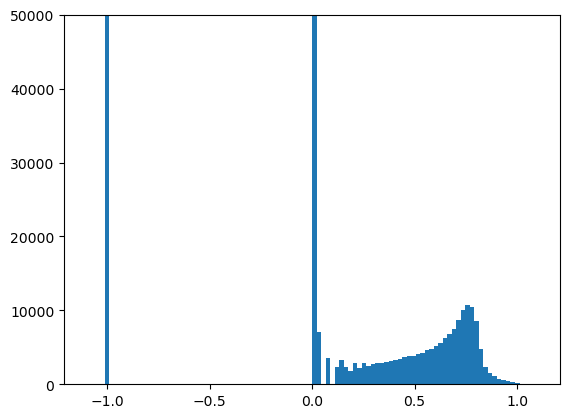

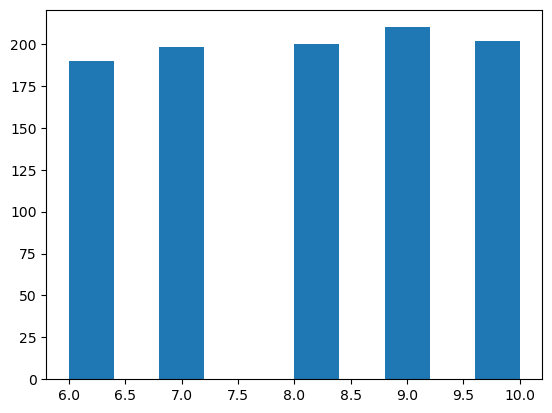

In [2]:
# visualize the NORMALIZED concentration distribution and the nr sensors distribution

all_conc    = []
all_sensors = []
for el in tqdm(collection):
    all_conc.append(el["con_sensors"])  
    all_sensors.append(el["n_sensors"])   
aaa = np.array(all_conc).reshape([-1])

plt.figure()
_ = plt.hist(aaa.reshape([-1]), bins=100, range=[-1.1, 1.1])
print(len(aaa))
plt.ylim(0, len(aaa)*0.05)
plt.figure()
_ = plt.hist(all_sensors, bins=10)

### Experiments

#### Minimum working example of a slider and constrained plot in Plotly

In [2]:
import plotly.graph_objects as go
import numpy as np

time = np.linspace(0, 9, 10)
sensors = np.random.rand(10, 2)
sources = np.random.rand(30, 2)


# define the figure object and add the static plots and traces here (initial plots also here!)
fig = go.Figure()
fig.add_trace(go.Scatter(x=sensors[:, 0], y=sensors[:, 1], mode="markers", name="Sensors"))
fig.add_trace(go.Scatter(x=sources[:, 0], y=sources[:, 1], mode="markers", name="Sources"))

# static layout constraints (initial annotations also here!)
fig.update_xaxes(range=[-1.2, 1.2], scaleanchor="y", scaleratio=1, constrain="domain")
fig.update_yaxes(range=[-1.2, 1.2], scaleanchor="x", scaleratio=1, constrain="domain")


# create different frames (one for each time t) ------------------------------------------------------------------------
frames = []
for t in time:
    wind_direc = np.random.rand()*2*np.pi
    wind_speed = np.random.rand()
        
    
    frames.append(go.Frame(
        # in data are all the plot / traces (like contourf, and scatter or lines)
        data = [],
        # one name for each frame (has to match up EXACTLY with the "args" in slider!)
        name = f"timestep {int(t)}",
        # here are all the layout modifications (annotations or formatting)
        layout = go.Layout(
            annotations=[
                dict(
                    x = 0.2 + wind_speed * np.cos(wind_direc), 
                    y = 0.2 + wind_speed * np.sin(wind_direc), 
                    ax = 0, 
                    ay = 0, 
                    xref="x", yref="y", axref="x", ayref="y",
                    showarrow=True, arrowhead=2, arrowsize=1.5, arrowwidth=2, arrowcolor="blue"
                )
            ]
        )
    ))
    
# Add all the frames to the figure -------------------------------------------------------------------------------------
fig.frames = frames

# Add the slider and play button ---------------------------------------------------------------------------------------
fig.update_layout(
    sliders = [
        # this is one slider (= one dict)
        dict(
            # the active controls the initial position of the slider (just use an index)
            active = 0, 
            # here a separate dict for each timestep is defined
            steps = [
                dict(
                    method = "animate", 
                    args = [
                        # this has the be the EXACT name of a frame (= list of frame names to be shown)
                        [f"timestep {int(t)}"], 
                        dict(
                            mode="immediate", 
                            frame = dict(duration = 500, redraw = True)
                            )
                        ],
                    # this is just how all the ticks are labelled ... (doesnt have to match with frame name)
                    label = f"asdf {t}"
                ) for t in time
            ],
            transition = dict(duration = 0),
            x = 0.1,
            xanchor = "left",
            y = 0,
            yanchor = "top",
            currentvalue = dict(prefix = "Step: ")
        )
    ]
)    
    
fig.show()

#### Minimum working example of modifying Gaussians through their covariance matrix

In [1]:
### Modifying Gaussian Test, needs wind speed and direction from the first script...

from scipy.stats import multivariate_normal

def create_scale_mtx(s):
    mtx = np.array([[1, 0], 
                    [0, s]])
    return mtx

def create_rotation_mtx(alpha):
    mtx = np.array([[np.cos(alpha), -np.sin(alpha)], 
                    [np.sin(alpha),  np.cos(alpha)]])
    return mtx

def apply_covariance_update(cov, s, alpha):
    # s is the amount that the covariance matrix should be shrunken by ACROSS the wind direction
    # alpha is the wind direction
    scl = create_scale_mtx(s)
    rot = create_rotation_mtx(alpha)
    cov = rot @ scl @ rot. T @ cov @ rot @ scl @ rot.T
    
    # returns the updated covariance matrix
    return cov


# Define mean and covariance matrix
mean       = np.array([0, 0]) 
stddv      = 0.15
covariance = np.array([[stddv, 0], 
                       [0, stddv]])  

covariance_new = covariance
covariance_old = covariance
for dir, spe in zip(wind_direc, wind_speed):
    scale_weight = 1 - 0.1 * min(1, spe * 2)
    covariance_new = apply_covariance_update(covariance_new, scale_weight, dir)

covariance = 0.03*covariance + covariance_new

# plot -----------------------------------------------------------------------------------------------------------------
# Create a grid of (x, y) coordinates
x, y = np.linspace(-1, 1, 256), np.linspace(-1, 1, 256)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# Calculate the Gaussian probability density function (PDF) at each point on the grid
rv = multivariate_normal(mean, covariance)
Z = rv.pdf(pos)
Z /= Z.max()

# Plot contour lines
fig, ax = plt.subplots()
contour = ax.contourf(X, Y, Z, levels=20, cmap="viridis")  # Adjust levels for detail
colorbar = fig.colorbar(contour, ax=ax, label="Concentration")
colorbar.ax.set_position([0.82, 0.1, 0.5, 0.6])  # [left, bottom, width, height]
ax.set_title("2D Gaussian Distribution Contour")
ax.set_aspect("equal", adjustable="box")
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2))
ax.grid(visible=True, color="lightgray")

NameError: name 'np' is not defined